# Laboratory Exercise 1: Food Delivery

City Delivery is a delivery service that brings meals from restaurants across Macedonia to the door. Its pages are a stored snapshot in `data/site`, and the setup serves them from this machine, so every request stays on the local loopback address. The orders are synthetic and describe no real restaurant, courier, or customer.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [64]:
import json
import re
import threading
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urljoin, urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from bs4.builder import HTML
from playwright.async_api import async_playwright
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
# Every random step draws from this generator, so a rerun gives the same result.
rng = np.random.default_rng(2026)

In [65]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [66]:
# Every path is a file under the site directory.
class Service(SimpleHTTPRequestHandler):
    extensions_map = {
        **SimpleHTTPRequestHandler.extensions_map,
        ".html": "text/html; charset=utf-8",
    }

    def log_message(self, format: str, *args: object) -> None:
        pass


# Port 0 lets the system choose a free port, so a second running notebook never collides.
server = ThreadingHTTPServer(("127.0.0.1", 0), partial(Service, directory=DATA / "site"))
threading.Thread(target=server.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{server.server_port}/"
BASE

'http://127.0.0.1:59845/'

## Task 1: Collect the Orders

#The service lists its delivered orders across several pages, and the first one is `catalogue/page-1.html` under `BASE`. Collect every order into a table named `orders`, with one row per order and these columns:

#- `order_id`, the identifier of the order,
#- `restaurant`, `cuisine`, and `city`,
#- `distance` and `unit`, the distance from the restaurant to the door and the unit it is quoted in, exactly as the order states them,
#- `minutes`, the minutes the delivery took,
#- `slot`, `weather`, `payment`, and `rating`, the stars out of 5 that the customer gave, and
#- `by_restaurant`, which is true when the restaurant delivered the order itself and false when a courier of the service did.

#An order that does not state a field has a missing value in that column. Report how many orders the service lists and over how many pages they are spread.

In [68]:
r = requests.get(urljoin(BASE, "catalogue/page-1.html"))
soup = BeautifulSoup(r.text, "html.parser")

#data
order_ids = []
restaraunts = []
cuisines = []
cities = []
distances = []
units = []
minutes = []
slots = []
weathers = []
payments = []
by_restaurants = []
ratings = []

for page in range(1, 17):
    r = requests.get(urljoin(BASE, f"catalogue/page-{page}.html"))
    r.raise_for_status()
    soup = BeautifulSoup(r.text, "html.parser")
    articles = soup.find_all("article", class_="card order")


    for article in articles:
        #order id
        order_id = article["data-id"]
        order_ids.append(order_id)
        #restaraunt name
        restaraunt = article.find("h2", class_="title").find("a").text
        restaraunts.append(restaraunt if restaraunt else None)

        #cuisine type
        cuisine = article.find("p", class_="place").find("span", class_="cuisine").text
        cuisines.append(cuisine if cuisine else None)

        #city
        city = article.find("span", class_="city").text
        cities.append(city if city else None)

        #delivery distance
        distance_summary = article.find("p", class_="summary").get_text(strip=True)
        dist = re.search(r"A trip of (.+?)\s+(\S+)\s+from", distance_summary)
        distance, unit = None, None
        if dist:
            distance, unit = dist.group(1), dist.group(2)
        distances.append(distance)
        units.append(unit)

        #delivery time
        try:
            delivery_summary = article.find("p", class_="delivery").text
        except AttributeError:
            delivery_summary = None
        try:
            delivery_time = int(re.search(r"Delivered in (\d+) minutes", delivery_summary).group(1))
        except TypeError:
            delivery_time = None
        minutes.append(delivery_time)

        #slot
        try:
            slot = article.find("li", class_="slot").get_text(strip=True)
        except AttributeError:
            slot = None
        slots.append(slot)

        #weather
        try:
            weather = article.find("li", class_="weather").get_text(strip=True)
        except AttributeError:
            weather = None
        weathers.append(weather)

        #payment
        try:
            payment = article.find("li", class_="payment").get_text(strip=True)
        except AttributeError:
            payment = None
        payments.append(payment)

        #rating
        try:
            rating = int(re.search(r"Rated (\d+) of 5", article.find("li", class_="rating").text).group(1))
        except (AttributeError, TypeError):
            rating = None
        ratings.append(rating)

        #by_restaurant
        try:
            courier_text = article.find("p", class_="courier").get_text(strip=True)
        except AttributeError:
            courier_text = None

        if courier_text is None:
            by_restaurant = None
        else:
            by_restaurant = "restaurant" in courier_text.lower()
        by_restaurants.append(by_restaurant)



orders = pd.DataFrame({
    "order_id": order_ids, "restaurant": restaraunts, "cuisine": cuisines,
    "city": cities, "distance": distances, "unit": units, "minutes": minutes,
    "slot": slots, "weather": weathers, "payment": payments,
    "rating": ratings, "by_restaurant": by_restaurants,
})

orders["minutes"] = orders["minutes"].astype("Int64")
orders["rating"] = orders["rating"].astype("Int64")

print(orders.shape)
print(orders.dtypes)
orders.head(20)



(192, 12)
order_id           str
restaurant         str
cuisine            str
city               str
distance           str
unit               str
minutes          Int64
slot               str
weather            str
payment            str
rating           Int64
by_restaurant     bool
dtype: object


,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23,Late night,Clear,Cash,5,False
1,283894,Pizza House,Pizza,Skopje,3 650,m,30,Lunch,Clear,Card,3,False
2,832866,Sushi Bar,Sushi,Skopje,4 700,m,<NA>,Lunch,Rain,Cash,3,True
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25,Lunch,Rain,Card,4,False
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26,Late night,Clear,Card,4,True
5,101854,Salad Bowl,Salad,Skopje,3.6,km,25,Dinner,Clear,Cash,5,False
6,855520,Bakery Plus,Pastries,Ohrid,3.2,km,20,Lunch,Clear,Card,3,False
7,332602,Snack Corner,Small plates,Kumanovo,1.7,km,25,Late night,Clear,Cash,4,False
8,826931,City Grill,Grill,Skopje,3.9,km,30,Lunch,Clear,Card,3,False
9,599834,Burger Bar 7,Burgers,Skopje,4 450,m,72,Late night,Rain,Card,1,False


## Task 2: Add the Receipts

#The home page of the service, `index.html` under `BASE`, points to a page of receipts.
# Collect every receipt the page holds, and add the items, the #total, and the tip of each order to `orders`, so that every order appears exactly once. #Name the result `df`.

#Report how many receipts the page says it holds, how many you collected, and what you did about any receipt that would put an order in `df` more than once.

In [70]:
r = requests.get(urljoin(BASE, "index.html"))
home = BeautifulSoup(r.text, "html.parser")

# look for the link to the receipts page on the home page
for a in home.find_all("a"):
    print(a.get_text(strip=True), "->", a.get("href"))
receipts_link = home.find("a", string="receipts page")["href"]

g = requests.get(urljoin(BASE, receipts_link))
rec = BeautifulSoup(g.text, "html.parser")

# the table is empty in the html, JavaScript fills it in after the page opens
print("rows in the table:", len(rec.find_all("tr")))

# but the receipts are inside the script as a list
script_text = rec.find("script").get_text()
m = re.search(r"const RECEIPTS = (\[.*?\]);", script_text, re.DOTALL)
data = json.loads(m.group(1))
receipts = pd.DataFrame(data)
receipts["order_id"] = receipts["order_id"].astype(str)   # same type as in orders

# the counter on the page is written from the length of this list
print("counter built from RECEIPTS.length:", "RECEIPTS.length} receipts" in script_text)
receipts_said = len(data)
print(receipts.shape)

# receipts that repeat an order
dup_ids = receipts.loc[receipts["order_id"].duplicated(), "order_id"].unique()
print("orders with more than one receipt:", list(dup_ids))
print(receipts[receipts["order_id"].isin(dup_ids)])

# are the repeated receipts exact copies of each other?
repeated = receipts[receipts["order_id"].isin(dup_ids)]
identical = len(repeated.drop_duplicates()) == len(dup_ids)
print("exact copies:", identical)

# keep one receipt per order (if they were not copies we would have to choose one)
receipts_clean = receipts.drop_duplicates(subset="order_id", keep="first")

df = orders.merge(receipts_clean, on="order_id", how="left", validate="one_to_one")

print("receipts without an order in orders:", (~receipts_clean["order_id"].isin(orders["order_id"])).sum())
print("orders without a receipt:", df["total"].isna().sum())
print(df.shape, "| every order once:", df["order_id"].is_unique)
print(f"The page says it holds {receipts_said} receipts, I collected {len(receipts)}. "
      f"{len(receipts) - len(receipts_clean)} receipt(s) repeated an order, so I dropped the extra copy and df has {len(df)} orders, each once.")
df.head()


City Delivery -> index.html
Home -> index.html
Browse -> catalogue/page-1.html
Help -> #
Browse the orders -> catalogue/page-1.html
receipts page -> receipts.html
rows in the table: 0
counter built from RECEIPTS.length: True
(193, 4)
orders with more than one receipt: ['510546']
    order_id  items  total  tip
99    510546      4   1180    0
100   510546      4   1180    0
exact copies: True
receipts without an order in orders: 0
orders without a receipt: 0
(192, 15) | every order once: True
The page says it holds 193 receipts, I collected 193. 1 receipt(s) repeated an order, so I dropped the extra copy and df has 192 orders, each once.


,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant,items,total,tip
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23,Late night,Clear,Cash,5,False,2,770,0
1,283894,Pizza House,Pizza,Skopje,3 650,m,30,Lunch,Clear,Card,3,False,4,860,60
2,832866,Sushi Bar,Sushi,Skopje,4 700,m,<NA>,Lunch,Rain,Cash,3,True,2,710,0
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25,Lunch,Rain,Card,4,False,3,1240,60
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26,Late night,Clear,Card,4,True,2,450,30


## Task 3: Describe the Orders

Answer each request below from `df`. Support each answer with the numbers that establish it, and with a figure wherever the request asks you to show something.

### 3.1 Column Types

Give every column of `df` a type that matches what it measures. The slots have a natural order, from lunch to late night, and the type of `slot` keeps it.

In [71]:
# Write your solution here.
# identifier -> text, not a number to calculate with
df["order_id"] = df["order_id"].astype("string")

# names and labels -> category
for col in ["restaurant", "cuisine", "city", "unit", "weather", "payment"]:
    df[col] = df[col].astype("category")

# slot has a natural order -> ordered category
slot_order = ["Lunch", "Dinner", "Late night"]
print(df["slot"].unique())
df["slot"] = pd.Categorical(df["slot"], categories=slot_order, ordered=True)

# distance is quoted like "3 650", so remove the spaces first, then make it a number
df["distance"] = (df["distance"].str.replace(r"\s", "", regex=True)
                  .str.replace(",", ".")
                  .astype(float))

# counts stay whole numbers but can be missing
for col in ["minutes", "rating", "items", "total", "tip"]:
    df[col] = df[col].astype("Int64")

# true / false, with missing allowed
df["by_restaurant"] = df["by_restaurant"].astype("boolean")

print(df.dtypes)
print("slot values lost by the conversion:", df["slot"].isna().sum())

<StringArray>
['Late night', 'Lunch', 'Dinner']
Length: 3, dtype: str
order_id           string
restaurant       category
cuisine          category
city             category
distance          float64
unit             category
minutes             Int64
slot             category
weather          category
payment          category
rating              Int64
by_restaurant     boolean
items               Int64
total               Int64
tip                 Int64
dtype: object
slot values lost by the conversion: 0


### 3.2 What Is Missing

Count the missing values in each column, show where they fall, and find out whether the absence of a value depends on another column.

order_id          0
restaurant        0
cuisine           0
city              0
distance          0
unit              0
minutes          42
slot              0
weather           0
payment           0
rating           24
by_restaurant     0
items             0
total             0
tip               0
dtype: int64


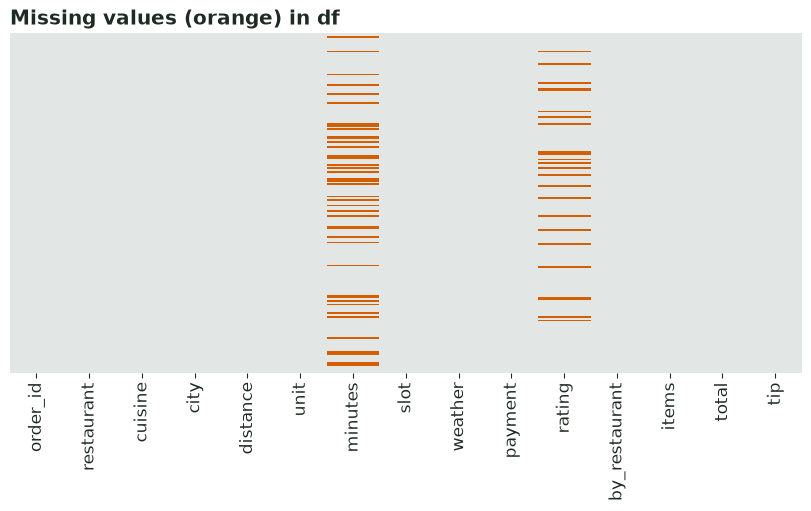

columns with missing values: ['minutes', 'rating']
    missing         column          test       p  p_holm  depends
0   minutes  by_restaurant    chi-square  0.0000     0.0     True
5   minutes        cuisine    chi-square  0.1100     1.0    False
11   rating        weather    chi-square  0.1224     1.0    False
15   rating          items  Mann-Whitney  0.1773     1.0    False
16   rating          total  Mann-Whitney  0.2212     1.0    False
13   rating           city    chi-square  0.2285     1.0    False
8   minutes            tip  Mann-Whitney  0.2384     1.0    False
7   minutes          total  Mann-Whitney  0.3807     1.0    False
3   minutes        payment    chi-square  0.4038     1.0    False
4   minutes           city    chi-square  0.4732     1.0    False
6   minutes          items  Mann-Whitney  0.5001     1.0    False
17   rating            tip  Mann-Whitney  0.5018     1.0    False
12   rating        payment    chi-square  0.6234     1.0    False
10   rating           slo

In [72]:
# Write your solution here.
# how many are missing in each column
missing = df.isna().sum()
print(missing)

# where do they fall? dark cell = missing
plt.figure(figsize=(8, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap=["#e2e6e4", "#D55E00"])
plt.title("Missing values (orange) in df")
plt.show()

# does a missing value depend on another column?
miss_cols = [c for c in df.columns if df[c].isna().any()]
print("columns with missing values:", miss_cols)

other_cat = ["by_restaurant", "slot", "weather", "payment", "city", "cuisine"]
other_num = ["items", "total", "tip"]
rows = []
for m in miss_cols:
    is_missing = df[m].isna()
    # categorical columns: chi-square test of independence
    for c in other_cat:
        if c == m:
            continue
        table = pd.crosstab(df[c], is_missing)
        chi2, p, dof, expected = stats.chi2_contingency(table)
        rows.append({"missing": m, "column": c, "test": "chi-square", "p": p})
    # numeric columns: compare the two groups with Mann-Whitney
    for c in other_num:
        if c == m:
            continue
        a = df.loc[is_missing, c].dropna().astype(float)
        b = df.loc[~is_missing, c].dropna().astype(float)
        p = stats.mannwhitneyu(a, b).pvalue
        rows.append({"missing": m, "column": c, "test": "Mann-Whitney", "p": p})

tests = pd.DataFrame(rows)
# many tests at once -> correct the p-values (Holm)
tests["p_holm"] = multipletests(tests["p"], method="holm")[1]
tests["depends"] = tests["p_holm"] < 0.05
print(tests.sort_values("p").round(4))

# look at the strongest one for each column with missing values
for m in miss_cols:
    best = tests[tests["missing"] == m].sort_values("p").iloc[0]["column"]
    print()
    print(f"{m} missing vs {best}")
    if best in other_cat:
        print(pd.crosstab(df[best], df[m].isna(), margins=True))
    else:
        print(df.groupby(df[m].isna())[best].describe())

### 3.3 Distances in Two Units

Some orders quote the distance in metres and others in kilometres. Compare the quoted distances within each unit, then add a column `distance_km` that states every distance in kilometres.

unit
km    162
m      30
Name: count, dtype: int64
      count         mean          std     min     25%     50%     75%     max
unit                                                                         
km    162.0     3.230247     1.276013     1.3     2.3     2.9     4.1     8.0
m      30.0  2498.333333  1066.777562  1200.0  1650.0  2375.0  2887.5  5350.0


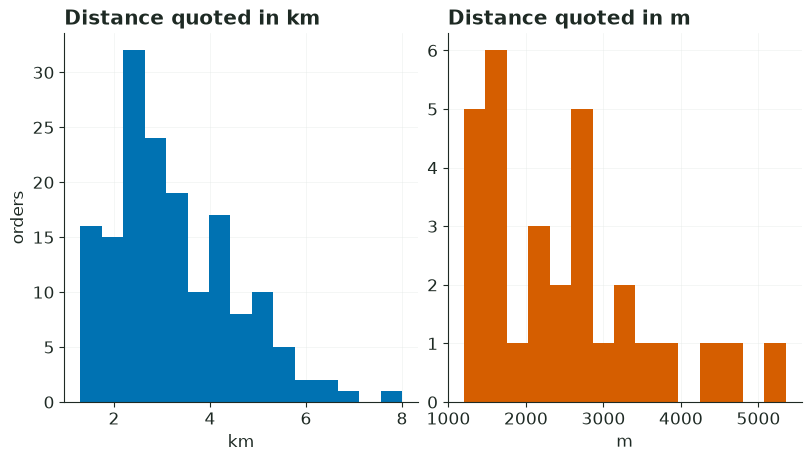

      count      mean       std  min   25%    50%     75%   max
unit                                                           
km    162.0  3.230247  1.276013  1.3  2.30  2.900  4.1000  8.00
m      30.0  2.498333  1.066778  1.2  1.65  2.375  2.8875  5.35
Mann-Whitney p-value, km group vs m group: 0.002178672113834181
units found: ['km', 'm']


,distance,unit,distance_km
0,5.0,km,5.00
1,3650.0,m,3.65
2,4700.0,m,4.70
3,2.7,km,2.70
4,2.4,km,2.40


In [73]:
# Write your solution here.
print(df["unit"].value_counts(dropna=False))

# the quoted distances, each unit on its own (the numbers are not in the same unit yet)
print(df.groupby("unit", observed=True)["distance"].describe())

fig, axes = plt.subplots(1, 2)
for ax, u in zip(axes, ["km", "m"]):
    ax.hist(df.loc[df["unit"] == u, "distance"].dropna(), bins=15, color=PALETTE[0] if u == "km" else PALETTE[1])
    ax.set_title(f"Distance quoted in {u}")
    ax.set_xlabel(u)
axes[0].set_ylabel("orders")
plt.show()

# everything in kilometres
df["distance_km"] = np.where(df["unit"] == "m", df["distance"] / 1000, df["distance"])

# now the two groups can be compared
print(df.groupby("unit", observed=True)["distance_km"].describe())
km_part = df.loc[df["unit"] == "km", "distance_km"].dropna()
m_part = df.loc[df["unit"] == "m", "distance_km"].dropna()
print("Mann-Whitney p-value, km group vs m group:", stats.mannwhitneyu(km_part, m_part).pvalue)
print("units found:", sorted(df["unit"].dropna().unique()))
df[["distance", "unit", "distance_km"]].head()

### 3.4 The Delivery Time

Describe the delivery time by its centre, its spread, and the shape of its distribution, and show the distribution. Decide which summary of the centre describes a typical order better.

n           150.00
mean         29.78
median       27.00
std          10.28
IQR          11.00
min          12.00
max          72.00
skewness      1.41
kurtosis      2.42
dtype: float64


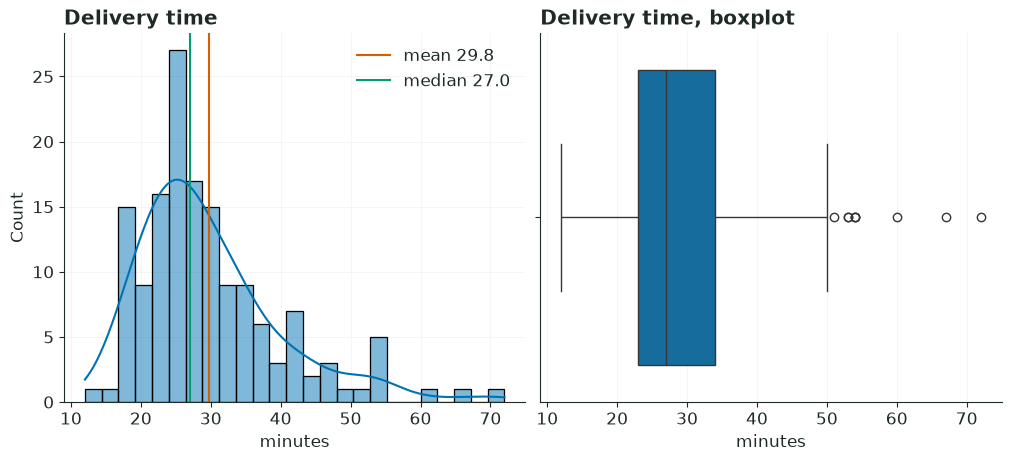

skewness 1.41: the distribution is skewed, the long tail pulls the mean (29.8) away from the median (27.0). The median describes a typical order better.


In [74]:
# Write your solution here.
times = df.dropna(subset=["minutes"]).copy()
times["minutes"] = times["minutes"].astype(float)
t = times["minutes"]

q1, q3 = t.quantile(0.25), t.quantile(0.75)
summary = pd.Series({
    "n": len(t),
    "mean": t.mean(),
    "median": t.median(),
    "std": t.std(),
    "IQR": q3 - q1,
    "min": t.min(),
    "max": t.max(),
    "skewness": stats.skew(t),
    "kurtosis": stats.kurtosis(t),
})
print(summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
sns.histplot(t, bins=25, kde=True, color=PALETTE[0], ax=axes[0])
axes[0].axvline(t.mean(), color=PALETTE[1], label=f"mean {t.mean():.1f}")
axes[0].axvline(t.median(), color=PALETTE[2], label=f"median {t.median():.1f}")
axes[0].set_title("Delivery time")
axes[0].set_xlabel("minutes")
axes[0].legend()
sns.boxplot(x=t, color=PALETTE[0], ax=axes[1])
axes[1].set_title("Delivery time, boxplot")
axes[1].set_xlabel("minutes")
plt.show()

if abs(summary["skewness"]) > 0.5:
    print(f"skewness {summary['skewness']:.2f}: the distribution is skewed, the long tail pulls the mean "
          f"({t.mean():.1f}) away from the median ({t.median():.1f}). The median describes a typical order better.")
else:
    print("the distribution is roughly symmetric, the mean and the median are close, the mean is fine.")

### 3.5 Delivery Time by Slot

Compare the delivery time across the slots.

            count   mean    std   min    25%   50%   75%   max
slot                                                          
Lunch        45.0  28.93   9.61  12.0  23.00  27.0  31.0  54.0
Dinner       61.0  30.75   9.50  16.0  24.00  28.0  35.0  54.0
Late night   44.0  29.30  11.99  17.0  22.75  26.0  32.0  72.0


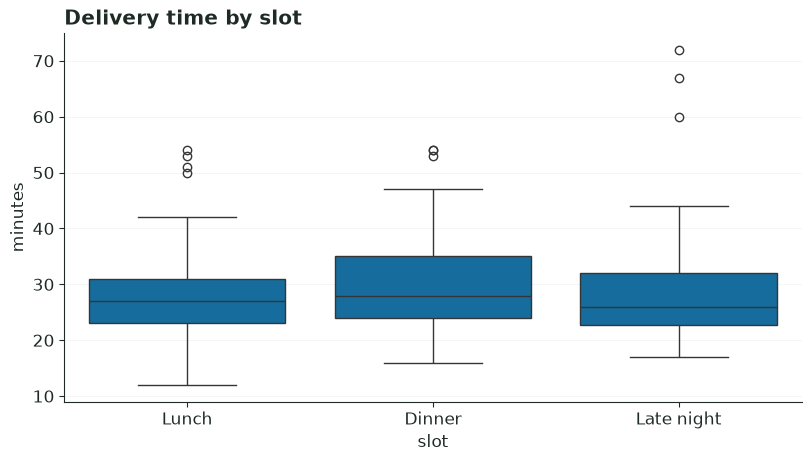

Kruskal-Wallis: H = 2.24 , p = 0.3258168601499362
No clear difference between the slots.


In [75]:
# Write your solution here.
print(times.groupby("slot", observed=True)["minutes"].describe().round(2))

sns.boxplot(data=times, x="slot", y="minutes", order=slot_order, color=PALETTE[0])
plt.title("Delivery time by slot")
plt.show()

# the times are skewed, so compare the slots with Kruskal-Wallis
groups = [g["minutes"] for _, g in times.groupby("slot", observed=True)]
kw = stats.kruskal(*groups)
print("Kruskal-Wallis: H =", round(kw.statistic, 2), ", p =", kw.pvalue)
medians = times.groupby("slot", observed=True)["minutes"].median()
if kw.pvalue < 0.05:
    print(f"The slots differ. The highest median is in {medians.idxmax()} ({medians.max()} min), the lowest in {medians.idxmin()} ({medians.min()} min).")
else:
    print("No clear difference between the slots.")

### 3.6 Orders by City

Show how the orders are spread across the cities, and give the share of orders in each city.

          orders  share %
city                     
Skopje        99     51.6
Tetovo        24     12.5
Kumanovo      22     11.5
Bitola        18      9.4
Ohrid         15      7.8
Prilep        14      7.3
orders with no city: 0


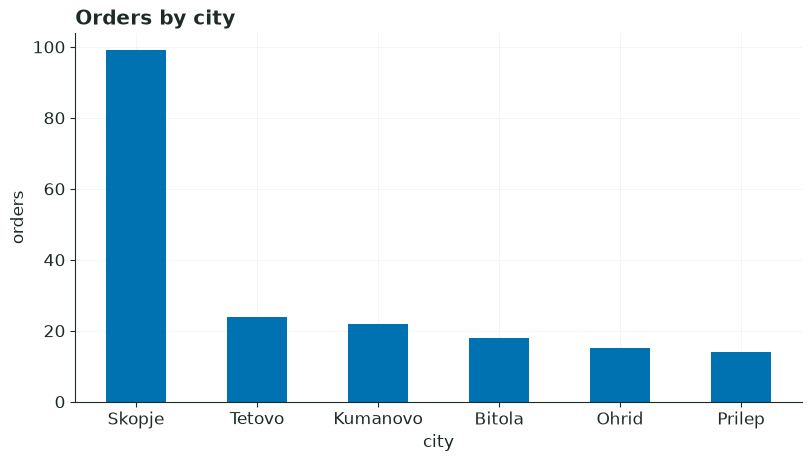

In [76]:
# Write your solution here.
counts = df["city"].value_counts()
shares = (counts / counts.sum() * 100).round(1)
print(pd.DataFrame({"orders": counts, "share %": shares}))
print("orders with no city:", df["city"].isna().sum())

counts.plot.bar(color=PALETTE[0])
plt.title("Orders by city")
plt.ylabel("orders")
plt.xticks(rotation=0)
plt.show()

### 3.7 Items and Total

Show how the number of items and the total of an order move together, and measure how strongly they do. Decide whether the relationship is close to a straight line.

Pearson r  = 0.881
Spearman r = 0.869
R squared of the line = 0.775 | slope = 291.7 MKD per item
       count    mean    std
items                      
1.0       29   295.0   73.0
2.0       48   615.0  156.0
3.0       59   864.0  234.0
4.0       27  1139.0  251.0
5.0       21  1441.0  361.0
6.0        3  1447.0   50.0
7.0        4  2255.0  202.0
8.0        1  2840.0    NaN


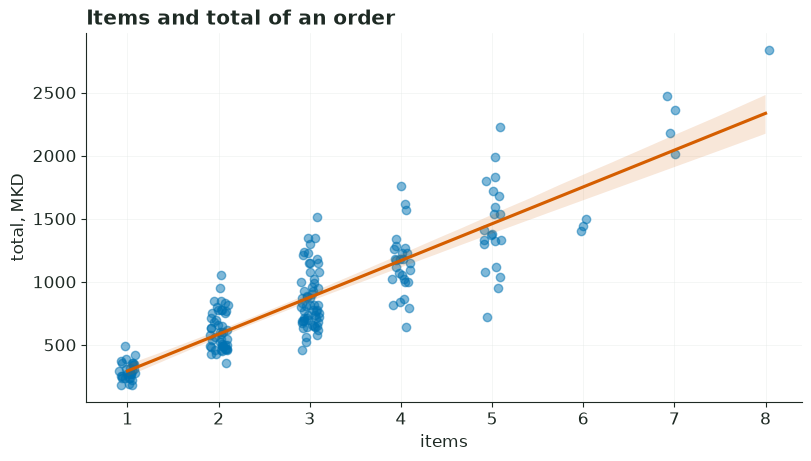

r = 0.88 and rho = 0.87 are close and high: the relationship is close to a straight line, about 292 MKD for every extra item.
The spread of the total grows: std 73 for 1 item(s) and 361 for 5 items.


In [77]:
# Write your solution here.
both = df[["items", "total"]].dropna().astype(float)
x, y = both["items"], both["total"]

pearson = stats.pearsonr(x, y)
spearman = stats.spearmanr(x, y)
fit = stats.linregress(x, y)
print("Pearson r  =", round(pearson.statistic, 3))
print("Spearman r =", round(spearman.statistic, 3))
print("R squared of the line =", round(fit.rvalue ** 2, 3), "| slope =", round(fit.slope, 1), "MKD per item")

# average total and spread for each number of items
by_items = both.groupby("items")["total"].agg(["count", "mean", "std"]).round(0)
print(by_items)

sns.regplot(x=x, y=y, x_jitter=0.1, scatter_kws={"alpha": 0.5, "color": PALETTE[0]}, line_kws={"color": PALETTE[1]})
plt.title("Items and total of an order")
plt.xlabel("items")
plt.ylabel("total, MKD")
plt.show()

# strong, and Pearson is close to Spearman (no big curve in the cloud)
if pearson.statistic > 0.8 and abs(pearson.statistic - spearman.statistic) < 0.05:
    print(f"r = {pearson.statistic:.2f} and rho = {spearman.statistic:.2f} are close and high: the relationship is close to a straight line, "
          f"about {fit.slope:.0f} MKD for every extra item.")
else:
    print("The relationship is not close to a straight line.")

# but the scatter around the line grows with the number of items
big = by_items[by_items["count"] >= 5]
print(f"The spread of the total grows: std {big['std'].iloc[0]:.0f} for {big.index[0]:.0f} item(s) and {big["std"].iloc[-1]:.0f} for {big.index[-1]:.0f} items.")

### 3.8 Every Pair of Numeric Columns

Show how strongly every pair of numeric columns moves together, measured by the Spearman correlation, and name the pair that moves together most strongly.

             distance_km  minutes  rating  items  total   tip
distance_km         1.00     0.59   -0.31  -0.00   0.00  0.02
minutes             0.59     1.00   -0.42  -0.07  -0.04  0.07
rating             -0.31    -0.42    1.00   0.08   0.09 -0.04
items              -0.00    -0.07    0.08   1.00   0.87  0.42
total               0.00    -0.04    0.09   0.87   1.00  0.46
tip                 0.02     0.07   -0.04   0.42   0.46  1.00


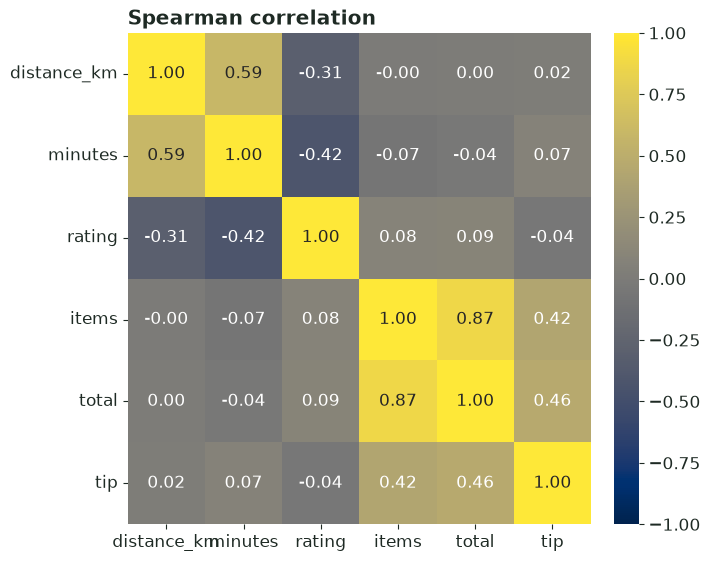

                     pair     rho       p  abs_rho
12          items - total  0.8691  0.0000   0.8691
0   distance_km - minutes  0.5896  0.0000   0.5896
14            total - tip  0.4634  0.0000   0.4634
13            items - tip  0.4228  0.0000   0.4228
5        minutes - rating -0.4153  0.0000   0.4153
1    distance_km - rating -0.3095  0.0000   0.3095
10         rating - total  0.0883  0.2551   0.0883
9          rating - items  0.0819  0.2910   0.0819
8           minutes - tip  0.0711  0.3872   0.0711
6         minutes - items -0.0664  0.4196   0.0664
11           rating - tip -0.0412  0.5962   0.0412
7         minutes - total -0.0358  0.6638   0.0358
4       distance_km - tip  0.0209  0.7736   0.0209
2     distance_km - items -0.0049  0.9467   0.0049
3     distance_km - total  0.0028  0.9696   0.0028
The pair that moves together most strongly: items - total (rho = 0.869)


In [78]:
# Write your solution here.
from itertools import combinations

num_cols = ["distance_km", "minutes", "rating", "items", "total", "tip"]
nums = df[num_cols].astype(float)

corr = nums.corr(method="spearman")
print(corr.round(2))

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="cividis")
plt.title("Spearman correlation")
plt.show()

# every pair once, with its p-value
pairs = []
for a, b in combinations(num_cols, 2):
    res = stats.spearmanr(nums[a], nums[b], nan_policy="omit")
    pairs.append({"pair": f"{a} - {b}", "rho": res.statistic, "p": res.pvalue})
pairs = pd.DataFrame(pairs)
pairs["abs_rho"] = pairs["rho"].abs()
pairs = pairs.sort_values("abs_rho", ascending=False)
print(pairs.round(4))

top = pairs.iloc[0]
print(f"The pair that moves together most strongly: {top['pair']} (rho = {top['rho']:.3f})")

### 3.9 Delivery Time by City and Slot

Find the combination of city and slot with the highest median delivery time, counting only the combinations with at least three orders that state a delivery time.

In [79]:
# Write your solution here.
g = times.groupby(["city", "slot"], observed=True)["minutes"].agg(["count", "median"]).reset_index()

# only combinations with at least 3 orders that state a delivery time
g = g[g["count"] >= 3].sort_values("median", ascending=False)
print(g.head(10))

best = g[g["median"] == g["median"].max()]
print()
print("Highest median delivery time:")
print(best)

        city        slot  count  median
10    Prilep      Dinner      5    35.0
15    Tetovo       Lunch      3    34.0
4   Kumanovo      Dinner      6    33.5
17    Tetovo  Late night      5    32.0
8      Ohrid  Late night      3    32.0
3   Kumanovo       Lunch      8    29.5
16    Tetovo      Dinner      8    29.5
0     Bitola       Lunch      4    28.5
13    Skopje      Dinner     35    28.0
9     Prilep       Lunch      3    27.0

Highest median delivery time:
      city    slot  count  median
10  Prilep  Dinner      5    35.0


## Task 4: Delivery Times

Use a significance level of 5 % and a confidence level of 95 % for every decision and every range in this task and the next. For each question, state the decision and give the range beside it. The questions of this task concern the orders that state a delivery time.

### 4.1 The Advertised Time

The home page states an average delivery time. Decide whether the average delivery time of the orders differs from that statement, and give a range for the average delivery time.

In [80]:
# Write your solution here.
# the average the home page advertises
advertised = int(re.search(r"(\d+)\s+minutes on average", home.get_text()).group(1))
print("advertised average:", advertised, "minutes")

t = times["minutes"]
n = len(t)
res = stats.ttest_1samp(t, advertised)

# 95 % range for the mean
low, high = stats.t.interval(0.95, df=n - 1, loc=t.mean(), scale=stats.sem(t))

print("n =", n, "| sample mean =", round(t.mean(), 2))
print("t =", round(res.statistic, 3), ", p =", res.pvalue)
print(f"95 % range for the average delivery time: {low:.2f} to {high:.2f} minutes")
if res.pvalue < 0.05:
    print(f"Decision: reject H0, the average delivery time differs from the advertised {advertised} minutes.")
else:
    print(f"Decision: do not reject H0, no evidence that the average differs from {advertised} minutes.")

advertised average: 28 minutes
n = 150 | sample mean = 29.78
t = 2.12 , p = 0.035672962210614674
95 % range for the average delivery time: 28.12 to 31.44 minutes
Decision: reject H0, the average delivery time differs from the advertised 28 minutes.


### 4.2 Rain and Clear Weather

Decide whether the orders delivered in rain and in clear weather differ in their average delivery time, and give a range for the difference, taken as rain minus clear.


In [81]:
# Write your solution here.
rain = times.loc[times["weather"] == "Rain", "minutes"]
clear = times.loc[times["weather"] == "Clear", "minutes"]
print("rain: n =", len(rain), ", mean =", round(rain.mean(), 2), "| clear: n =", len(clear), ", mean =", round(clear.mean(), 2))

# Welch t-test, the two groups do not need the same variance
res = stats.ttest_ind(rain, clear, equal_var=False)

# 95 % range for the difference rain - clear
diff = rain.mean() - clear.mean()
v1 = rain.var(ddof=1) / len(rain)
v2 = clear.var(ddof=1) / len(clear)
se = np.sqrt(v1 + v2)
dof = (v1 + v2) ** 2 / (v1 ** 2 / (len(rain) - 1) + v2 ** 2 / (len(clear) - 1))
t_crit = stats.t.ppf(0.975, dof)
low, high = diff - t_crit * se, diff + t_crit * se

print("t =", round(res.statistic, 3), ", p =", res.pvalue)
print(f"difference rain - clear = {diff:.2f} minutes, 95 % range: {low:.2f} to {high:.2f}")
if res.pvalue < 0.05:
    print("Decision: reject H0, the average delivery time in rain and in clear weather differs.")
else:
    print("Decision: do not reject H0, no evidence of a difference.")

rain: n = 45 , mean = 32.78 | clear: n = 105 , mean = 28.5
t = 2.196 , p = 0.031371648323607615
difference rain - clear = 4.28 minutes, 95 % range: 0.39 to 8.17
Decision: reject H0, the average delivery time in rain and in clear weather differs.


## Task 5: Slots and Payments

The questions of this task concern all orders.

### 5.1 Payment by Slot

Decide whether the payment method depends on the slot of an order, and give a range for the share of cash payments in each slot, using a percentile bootstrap.

payment     Card  Cash
slot                  
Lunch         49     7
Dinner        57    22
Late night    34    23
expected counts:
payment     Card  Cash
slot                  
Lunch       40.8  15.2
Dinner      57.6  21.4
Late night  41.6  15.4
cells with expected count below 5: 0
chi-square = 11.135 , dof = 2 , p = 0.003820197333558141
Decision: reject H0, the payment method depends on the slot.
         slot  orders  cash share    low   high
0       Lunch      56       0.125  0.054  0.214
1      Dinner      79       0.278  0.190  0.380
2  Late night      57       0.404  0.281  0.526


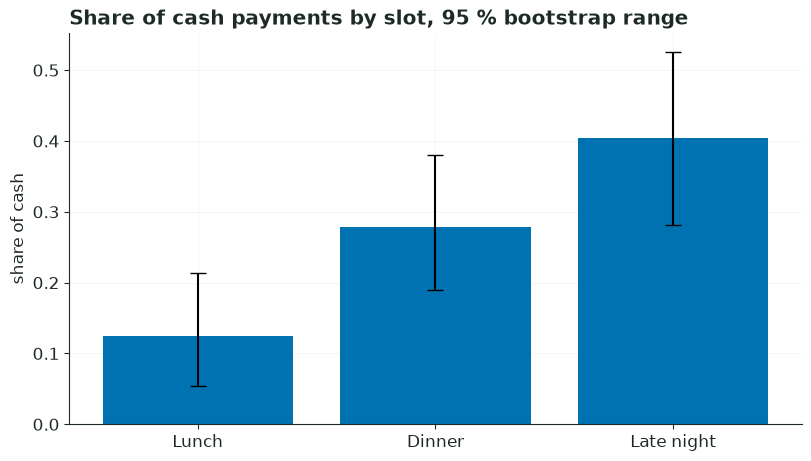

In [82]:
# Write your solution here.
pay = df.dropna(subset=["slot", "payment"])
table = pd.crosstab(pay["slot"], pay["payment"])
print(table)

chi2, p, dof, expected = stats.chi2_contingency(table)
print("expected counts:")
print(pd.DataFrame(expected, index=table.index, columns=table.columns).round(1))
print("cells with expected count below 5:", (expected < 5).sum())
print("chi-square =", round(chi2, 3), ", dof =", dof, ", p =", p)
if p < 0.05:
    print("Decision: reject H0, the payment method depends on the slot.")
else:
    print("Decision: do not reject H0, no evidence that the payment method depends on the slot.")

# percentile bootstrap for the share of cash in each slot
B = 10000
res_rows = []
for s in slot_order:
    is_cash = (pay.loc[pay["slot"] == s, "payment"] == "Cash").to_numpy()
    sample = rng.choice(is_cash, size=(B, len(is_cash)), replace=True)
    boot = sample.mean(axis=1)
    low, high = np.percentile(boot, [2.5, 97.5])
    res_rows.append({"slot": s, "orders": len(is_cash), "cash share": is_cash.mean(), "low": low, "high": high})
cash = pd.DataFrame(res_rows)
print(cash.round(3))

plt.bar(cash["slot"], cash["cash share"], color=PALETTE[0],
        yerr=[cash["cash share"] - cash["low"], cash["high"] - cash["cash share"]], capsize=6)
plt.title("Share of cash payments by slot, 95 % bootstrap range")
plt.ylabel("share of cash")
plt.show()

### 5.2 The Mix of Slots

The home page states how the orders divide among the slots. Decide whether the orders match that statement, and give a range for the share of late-night orders, using a percentile bootstrap.

In [83]:
# Write your solution here.
# what the home page says about the slots
found = re.search(r"(\d+)\s*%\s*lunch,\s*(\d+)\s*%\s*dinner,\s*and\s*(\d+)\s*%\s*late night", home.get_text())
claimed = [int(found.group(i)) / 100 for i in (1, 2, 3)]
print("claimed shares (lunch, dinner, late night):", claimed)

counts = df["slot"].value_counts().reindex(slot_order)
expected = np.array(claimed) * counts.sum()
print(pd.DataFrame({"observed": counts, "expected": expected.round(1)}))

# goodness of fit test against the claimed shares
gof = stats.chisquare(counts, f_exp=expected)
print("chi-square =", round(gof.statistic, 3), ", p =", gof.pvalue)
if gof.pvalue < 0.05:
    print("Decision: reject H0, the orders do not match the statement of the home page.")
else:
    print("Decision: do not reject H0, the orders match the statement of the home page.")

# percentile bootstrap for the share of late night orders
known = df["slot"].dropna()
is_late = (known == "Late night").to_numpy()
B = 10000
sample = rng.choice(is_late, size=(B, len(is_late)), replace=True)
boot = sample.mean(axis=1)
low, high = np.percentile(boot, [2.5, 97.5])
print(f"share of late night orders: {is_late.mean():.3f}, 95 % bootstrap range: {low:.3f} to {high:.3f}")
print("claimed share 0.20 is", "inside" if low <= 0.20 <= high else "outside", "the range")

claimed shares (lunch, dinner, late night): [0.35, 0.45, 0.2]
            observed  expected
slot                          
Lunch             56      67.2
Dinner            79      86.4
Late night        57      38.4
chi-square = 11.51 , p = 0.0031671631995379436
Decision: reject H0, the orders do not match the statement of the home page.
share of late night orders: 0.297, 95 % bootstrap range: 0.234 to 0.365
claimed share 0.20 is outside the range


In [84]:
server.shutdown()